📊 01. Análisis Exploratorio de Datos (EDA) - Segmentación de Clientes
Este documento contiene la estructura formal del notebook de análisis exploratorio para el proyecto de clasificación multiclase de clientes del sector automovilístico.

# 📊 01. Análisis Exploratorio de Datos (EDA) - Segmentación de Clientes
Este documento contiene el análisis exploratorio para el proyecto de clasificación multiclase de clientes del sector automovilístico. Todo el análisis descriptivo y visual se realiza exclusivamente sobre el conjunto de entrenamiento (`train_70.csv`, 5,647 registros) para evitar fuga de datos (*data leakage*).

---

## 1. Carga de Datos, Split Estratificado 70/15/15 e Infraestructura 📦
**Descripción:**  
Configuración del entorno visual (`seaborn` y `matplotlib`) y obtención de `Train.csv` desde Kaggle mediante `kagglehub` (descartando el `Test.csv` externo). Posteriormente, se ejecuta una única partición estratificada por `Segmentation` (`random_state=42`) en proporción **70% Train / 15% Validation / 15% Test**, exportando los tres bloques a la carpeta `data/` **con sus valores nulos intactos** para que el `Pipeline` en `src/` gestione la imputación y el *encoding*.

In [1]:
import os
import shutil
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

# Configuración del estilo visual
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Rutas locales dentro de la carpeta del proyecto
ruta_train_local = "data/Train.csv"
ruta_test_local = "data/Test.csv"

# Comprobar si los archivos ya existen en la carpeta local 'data/'
if not (os.path.exists(ruta_train_local) and os.path.exists(ruta_test_local)):
    print("Descargando dataset desde Kaggle...")
    path = kagglehub.dataset_download("kaushiksuresh147/customer-segmentation")
    os.makedirs('data', exist_ok=True)
    
    # Copiar Train.csv y Test.csv a la carpeta local 'data'
    shutil.copy(os.path.join(path, "Train.csv"), ruta_train_local)
    shutil.copy(os.path.join(path, "Test.csv"), ruta_test_local)
    print("¡Descarga y copia completadas en la carpeta data/!")
else:
    print("Los archivos locales Train.csv y Test.csv ya existen en data/.")

# Cargar los datasets
train_df = pd.read_csv(ruta_train_local)
test_df = pd.read_csv(ruta_test_local)

print(f"Dataset Train listo: {train_df.shape[0]} filas y {train_df.shape[1]} columnas.")
print(f"Dataset Test listo: {test_df.shape[0]} filas y {test_df.shape[1]} columnas.")

train_df.head()

Los archivos locales Train.csv y Test.csv ya existen en data/.
Dataset Train listo: 8068 filas y 11 columnas.
Dataset Test listo: 2627 filas y 11 columnas.


,ID,Gender,Ever_Married,Age,Graduated,Profession,Work_Experience,Spending_Score,Family_Size,Var_1,Segmentation
0,462809,Male,No,22,No,Healthcare,1.0,Low,4.0,Cat_4,D
1,462643,Female,Yes,38,Yes,Engineer,NaN,Average,3.0,Cat_4,A
2,466315,Female,Yes,67,Yes,Engineer,1.0,Low,1.0,Cat_6,B
3,461735,Male,Yes,67,Yes,Lawyer,0.0,High,2.0,Cat_6,B
4,462669,Female,Yes,40,Yes,Entertainment,NaN,High,6.0,Cat_6,A


In [3]:
# Tabla resumen de tipos, nulos y valores únicos en train_70
info_df = pd.DataFrame({
    'Tipo': train_df.dtypes,
    'Valores Nulos': train_df.isnull().sum(),
    '% Nulos': (train_df.isnull().sum() / len(train_df) * 100).round(2),
    'Valores Únicos': train_df.nunique()
})

print("--- RESUMEN DE VARIABLES EN TRAIN_70 ---")
display(info_df)

print("\n--- ESTADÍSTICOS DESCRIPTIVOS (NUMÉRICAS) ---")
display(train_df.drop(columns=['ID']).describe().round(2))

print("\n--- ESTADÍSTICOS DESCRIPTIVOS (CATEGÓRICAS) ---")
display(train_df.describe(include=['object', 'string']))

--- RESUMEN DE VARIABLES EN TRAIN_70 ---


,Tipo,Valores Nulos,% Nulos,Valores Únicos
ID,int64,0,0.00,8068
Gender,str,0,0.00,2
Ever_Married,str,140,1.74,2
Age,int64,0,0.00,67
Graduated,str,78,0.97,2
Profession,str,124,1.54,9
Work_Experience,float64,829,10.28,15
Spending_Score,str,0,0.00,3
Family_Size,float64,335,4.15,9
Var_1,str,76,0.94,7



--- ESTADÍSTICOS DESCRIPTIVOS (NUMÉRICAS) ---


,Age,Work_Experience,Family_Size
count,8068.00,7239.00,7733.00
mean,43.47,2.64,2.85
std,16.71,3.41,1.53
min,18.00,0.00,1.00
25%,30.00,0.00,2.00
50%,40.00,1.00,3.00
75%,53.00,4.00,4.00
max,89.00,14.00,9.00



--- ESTADÍSTICOS DESCRIPTIVOS (CATEGÓRICAS) ---


,Gender,Ever_Married,Graduated,Profession,Spending_Score,Var_1,Segmentation
count,8068,7928,7990,7944,8068,7992,8068
unique,2,2,2,9,3,7,4
top,Male,Yes,Yes,Artist,Low,Cat_6,D
freq,4417,4643,4968,2516,4878,5238,2268


## 2. Inspección General y Diagnóstico de Nulos 🔎
**Descripción:**  
Diagnóstico estructural de las `5,647` observaciones de `train_70`. Se revisan los tipos de datos, la cardinalidad y el porcentaje de valores nulos por columna (`Work_Experience`, `Family_Size`, `Ever_Married`, `Profession`, `Graduated`, `Var_1`) para documentar las reglas de imputación que se integrarán en el `Pipeline` de `src/`.

In [2]:
# Resumen de información general y nulos
info_df = pd.DataFrame({
    'Tipo': train_df.dtypes,
    'Valores Nulos': train_df.isnull().sum(),
    '% Nulos': (train_df.isnull().sum() / len(train_df) * 100).round(2),
    'Valores Únicos': train_df.nunique()
})

print("--- RESUMEN DE VARIABLES EN TRAIN ---")
info_df

--- RESUMEN DE VARIABLES EN TRAIN ---


,Tipo,Valores Nulos,% Nulos,Valores Únicos
ID,int64,0,0.00,8068
Gender,str,0,0.00,2
Ever_Married,str,140,1.74,2
Age,int64,0,0.00,67
Graduated,str,78,0.97,2
Profession,str,124,1.54,9
Work_Experience,float64,829,10.28,15
Spending_Score,str,0,0.00,3
Family_Size,float64,335,4.15,9
Var_1,str,76,0.94,7


## 3. Análisis Univariado (Distribución de Variables en `train_70`) 📈
**Descripción:**  
Estudio individual de la variable objetivo (`Segmentation`) y del resto de variables predictoras (numéricas y categóricas) dentro del conjunto `train_70` (5,647 registros).  
Se verifica que el muestreo estratificado conserva el equilibrio natural entre las cuatro clases ($D \approx 28.10\%$, $A \approx 24.44\%$, $C \approx 24.42\%$, $B \approx 23.04\%$) y se evalúa la asimetría de las variables continuas (`Age`, `Work_Experience`, `Family_Size`) para decidir el tipo de imputación más adecuado.

In [ ]:
# 1. Distribución de la variable objetivo (Segmentation)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
order_seg = ['A', 'B', 'C', 'D']

# Conteo absoluto
sns.countplot(data=train_df, x='Segmentation', order=order_seg, ax=axes[0], palette='Set2', hue='Segmentation', legend=False)
axes[0].set_title('Conteo de Clientes por Segmento (train_70)')
axes[0].set_ylabel('Número de Clientes')
for container in axes[0].containers:
    axes[0].bar_label(container, padding=3)

# Porcentaje relativo
seg_pct = train_df['Segmentation'].value_counts(normalize=True).reindex(order_seg) * 100
sns.barplot(x=seg_pct.index, y=seg_pct.values, ax=axes[1], palette='Set2', hue=seg_pct.index, legend=False)
axes[1].set_title('Proporción de Clases (%) en train_70')
axes[1].set_ylabel('Porcentaje (%)')
axes[1].set_ylim(0, 35)
for i, v in enumerate(seg_pct.values):
    axes[1].text(i, v + 0.8, f"{v:.2f}%", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

# 2. Distribución de variables numéricas (Histogramas + Boxplots)
num_cols = ['Age', 'Work_Experience', 'Family_Size']
fig, axes = plt.subplots(2, 3, figsize=(16, 8))

for i, col in enumerate(num_cols):
    # Histograma con KDE
    sns.histplot(train_df[col].dropna(), kde=True, ax=axes[0, i], color='steelblue', bins=20)
    axes[0, i].axvline(train_df[col].median(), color='red', linestyle='--', label=f"Mediana: {train_df[col].median():.1f}")
    axes[0, i].set_title(f'Distribución de {col}')
    axes[0, i].legend()
    
    # Boxplot para detectar outliers
    sns.boxplot(x=train_df[col].dropna(), ax=axes[1, i], color='lightsteelblue')
    axes[1, i].set_title(f'Boxplot de {col}')

plt.tight_layout()
plt.show()

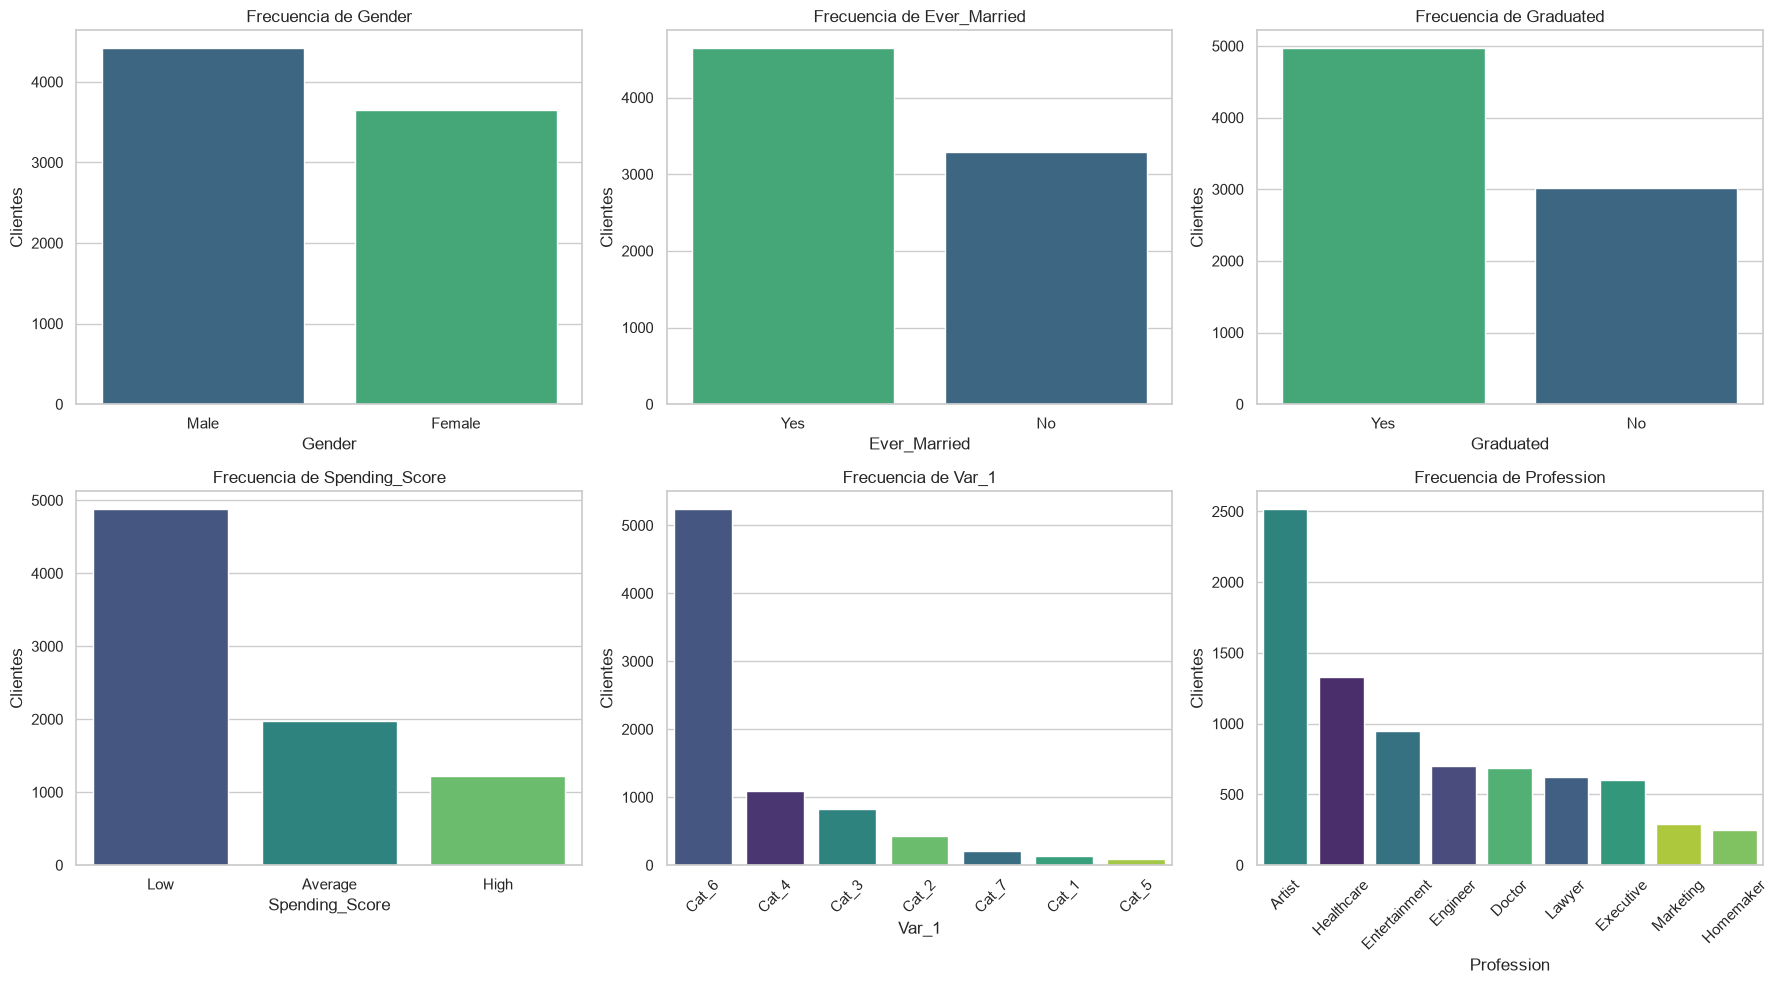

In [4]:
# 3. Distribución de variables categóricas
cat_cols = ['Gender', 'Ever_Married', 'Graduated', 'Spending_Score', 'Var_1', 'Profession']
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    order = train_df[col].value_counts().index
    sns.countplot(data=train_df, x=col, order=order, ax=axes[i], palette='viridis', hue=col, legend=False)
    axes[i].set_title(f'Frecuencia de {col}')
    axes[i].set_ylabel('Clientes')
    if col in ['Profession', 'Var_1']:
        axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()